# 05 — Tree-based models: decision tree, random forest, gradient boosting, AdaBoost

**Goal of this notebook:** test whether flexible **tree models** predict log price better than ridge (Phase 5, grouped-CV R² ≈ 0.85), and find out what they reveal that linear models cannot: **thresholds** ("above 256 GB the price jumps") and **interactions** (a spec or a brand being worth more in one price tier than another).

Same rules as Phases 4–5: the **training set only** (558 phones), the **same 5 grouped folds** saved in `split.csv` (all storage variants of a phone in the same fold), and the same three metrics (R² on log price, median % price error, MAE in ₹). The test set stays locked until Phase 7. `random_state=42` everywhere.

**Features:** the same as Model B and ridge: the 9 numeric specs plus `chip_group` and `brand`. **Target:** `log_price`. Trees split on thresholds, so they do **not** need scaled features (a split "battery ≤ 5000" works the same in mAh or in standard deviations).

### Setup
Libraries, the training data, and the settings shared by every model below.

In [1]:
import sys
sys.path.insert(0, "../src")
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

from features import NUMERIC_FEATURES
from split import load_train_test, cv_folds

The training set (with and without the web-lookup phones, for section 6.8) and the feature lists.

In [2]:
pd.set_option("display.width", 200)
CATEGORICAL = ["chip_group", "brand"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL
train, _ = load_train_test(include_web_lookup=True)
train_name, _ = load_train_test(include_web_lookup=False)
y = train["log_price"]
print("training phones:", len(train), "| name-only:", len(train_name))

training phones: 558 | name-only: 555


**One pipeline for every tree model.** The numeric columns pass through unchanged ("passthrough"), and `chip_group` and `brand` are **one-hot encoded** (one 0/1 column per category). Unlike OLS, a tree does not need a reference category to be dropped. The ridge pipeline from Phase 5 (scaled numerics + all dummies) is defined too, because we compare against it later.

In [3]:
def make_tree_pipeline(model):
    # Encoding inside the pipeline is fitted on each fold's training part only. It also lets
    # permutation importance (section 6.5) shuffle the raw "brand" column as ONE feature.
    pre = ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("pre", pre), ("model", model)])

def make_linear_pipeline(model, numeric=NUMERIC_FEATURES):
    # Phase 5's pipeline: standardised numerics + all dummies (needed for ridge/lasso)
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("pre", pre), ("model", model)])

def clean_names(pipe):
    # "num__log2_ram" -> "log2_ram", "cat__brand_Apple" -> "brand_Apple"
    return [n.replace("num__", "").replace("cat__", "") for n in pipe.named_steps["pre"].get_feature_names_out()]

**Scoring and cross-validation**, the same as notebooks 03 and 04. `cross_validate` fits a fresh copy (`clone`) of the pipeline on 4 folds and predicts the 5th, for each of the 5 saved folds. Besides the per-fold scores it returns the **out-of-fold predictions**: every phone predicted by the model that did *not* see it while fitting. We use those in section 6.6.

In [4]:
def score(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    # R² = 1 − RSS / TSS, on the log scale
    r2 = 1 - np.sum((y_true_log - y_pred_log) ** 2) / np.sum((y_true_log - y_true_log.mean()) ** 2)
    price_true, price_pred = np.exp(y_true_log), np.exp(y_pred_log)   # back to rupees
    return {"R²": r2,
            "median % error": 100 * np.median(np.abs(price_pred / price_true - 1)),
            "MAE (₹)": np.mean(np.abs(price_pred - price_true))}

def cross_validate(pipe, data, features=FEATURES):
    scores, oof = [], pd.Series(np.nan, index=data.index)
    for fit_idx, val_idx in cv_folds(data):
        fit, val = data.iloc[fit_idx], data.iloc[val_idx]
        model = clone(pipe).fit(fit[features], fit["log_price"])
        pred = model.predict(val[features])
        oof.iloc[val_idx] = pred                    # out-of-fold prediction for these phones
        scores.append(score(val["log_price"], pred))
    return pd.DataFrame(scores), oof

Two small helpers for tables: `summary_row` stores the mean and standard deviation of each metric over the 5 folds (the format of the `results/cv_phase*.csv` files), and `show` prints such rows as "mean ± std". Then we load the Phase 5 comparison rows.

In [5]:
def summary_row(name, folds):
    # Mean and std over the 5 folds, in the same columns as results/cv_phase5.csv
    row = {"model": name}
    for metric, col in [("R²", "R2_log"), ("median % error", "median_pct_error"), ("MAE (₹)", "MAE_rupees")]:
        row[col + "_mean"] = folds[metric].mean()
        row[col + "_std"] = folds[metric].std()
    return row

def show(rows):
    # Summary rows -> readable "mean ± std" table
    t = pd.DataFrame(rows).set_index("model")
    return pd.DataFrame({
        "R² (log price)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(t["R2_log_mean"], t["R2_log_std"])],
        "median % error": [f"{m:.1f} ± {s:.1f}" for m, s in zip(t["median_pct_error_mean"], t["median_pct_error_std"])],
        "MAE (₹)": [f"{m:,.0f} ± {s:,.0f}" for m, s in zip(t["MAE_rupees_mean"], t["MAE_rupees_std"])]}, index=t.index)

phase5 = pd.read_csv("../results/cv_phase5.csv")    # baselines, OLS, ridge, lasso, elastic net
show(phase5)

,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"
Ridge,0.847 ± 0.019,18.3 ± 2.4,"11,588 ± 1,767"
Lasso,0.848 ± 0.019,18.0 ± 2.1,"11,633 ± 1,807"
Elastic net,0.848 ± 0.019,18.1 ± 2.0,"11,617 ± 1,813"


**Phase 5's chosen settings, recomputed here.** Later sections need ridge's α (for the comparison in 6.5–6.6) and Phase 7 needs all chosen settings in one file (6.7). We rerun the same three grid searches as notebook 04 (same grids, same folds), so this notebook stands on its own; the printed values must match Phase 5 (ridge α = 1.53, lasso α = 0.0014, elastic net α = 0.0017 with l1_ratio 0.8).

In [6]:
lin_searches = {}
for name, model, grid in [
        ("ridge", Ridge(), {"model__alpha": np.logspace(-3, 3, 50)}),
        ("lasso", Lasso(max_iter=50000), {"model__alpha": np.logspace(-4, 0, 50)}),
        ("elastic net", ElasticNet(max_iter=50000), {"model__alpha": np.logspace(-4, 0, 30), "model__l1_ratio": [0.2, 0.5, 0.8]})]:
    search = GridSearchCV(make_linear_pipeline(model), grid, cv=cv_folds(train),
                          scoring="neg_mean_squared_error", n_jobs=-1)
    lin_searches[name] = search.fit(train[FEATURES], y)
    print(f"{name:12s} best settings: {search.best_params_}")
ridge_alpha = lin_searches["ridge"].best_params_["model__alpha"]

ridge        best settings: {'model__alpha': np.float64(1.5264179671752334)}


lasso        best settings: {'model__alpha': np.float64(0.0013894954943731374)}


elastic net  best settings: {'model__alpha': np.float64(0.0017433288221999873), 'model__l1_ratio': 0.8}


## 6.1 A shallow decision tree: readable rules
A **regression tree** asks yes/no questions about one feature at a time. At the top it looks at every feature and every possible threshold (e.g. "storage ≤ 128 GB") and picks the one split that most reduces the **squared error**: after the split, each of the two groups is predicted by its own mean log price, and the best split makes those predictions as accurate as possible. It then repeats the same search inside each group. The final groups are called **leaves**; a leaf predicts the **mean log price of the training phones in it**. **Depth** is the number of questions on the way from the top to a leaf.

With `max_depth=3`, every phone is priced by at most 3 questions, so the whole model fits on one picture. We fit it on the full training set (for reading only; its CV score comes below).

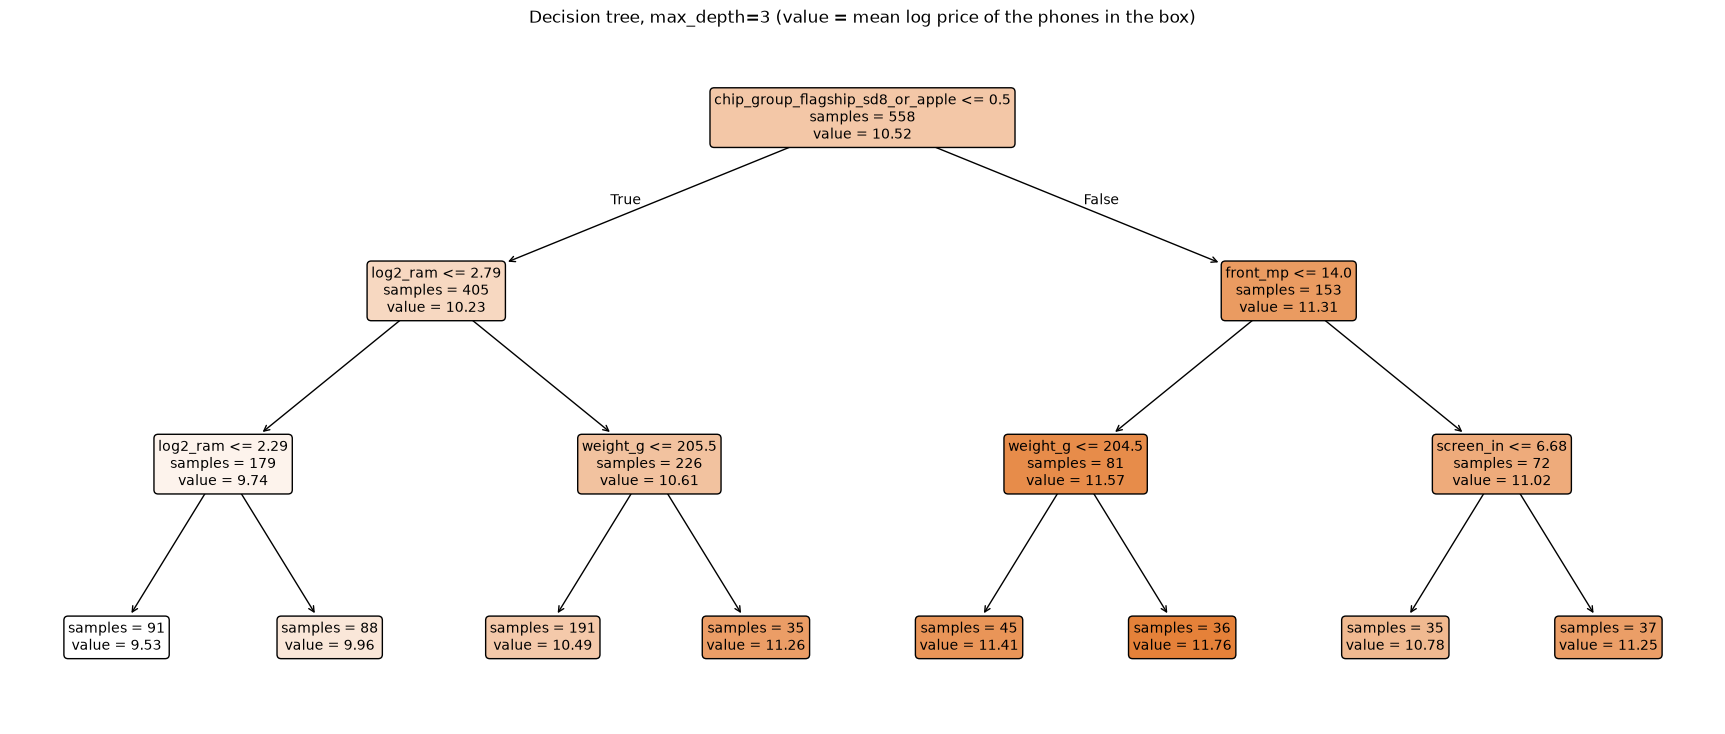

In [7]:
tree3 = make_tree_pipeline(DecisionTreeRegressor(max_depth=3, random_state=42)).fit(train[FEATURES], y)
tree_names = clean_names(tree3)

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree3.named_steps["model"], feature_names=tree_names, filled=True, rounded=True,
          precision=2, impurity=False, fontsize=10, ax=ax)
ax.set_title("Decision tree, max_depth=3 (value = mean log price of the phones in the box)")
plt.show()

**The same tree as plain-English rules.** We walk from the top to every leaf and write down the questions on the way. A one-hot column such as `brand_Apple` is 0 or 1, so its split at 0.5 means "brand is Apple" or "is not". For RAM and storage the tree splits on log2 values; we translate the threshold back to GB using the largest real value on the "≤" side. The price is exp(leaf value): the typical (geometric-mean) price of the phones in that leaf.

In [8]:
def rupees(x):
    # Indian digit grouping: 110000 -> "1,10,000"
    s = f"{round(x, -3):.0f}"
    head, tail = s[:-3], s[-3:]
    groups = []
    while len(head) > 2:
        groups.insert(0, head[-2:])
        head = head[:-2]
    return "₹" + ",".join(([head] if head else []) + groups + [tail])

def condition(name, threshold, go_left):
    if name.startswith("brand_") or name.startswith("chip_group_"):      # one-hot column: 0 or 1
        feature, value = name.split("_", 1) if name.startswith("brand_") else ("chip", name[len("chip_group_"):])
        return f"{feature} is {'NOT ' if go_left else ''}{value}"
    if name in ("log2_ram", "log2_storage"):                              # show GB instead of log2
        gb_col = "ram_gb" if name == "log2_ram" else "storage_gb"
        gb = train.loc[train[gb_col] <= 2 ** threshold, gb_col].max()
        return f"{gb_col[:-3]} {'≤' if go_left else '>'} {gb:g} GB"
    return f"{name} {'≤' if go_left else '>'} {threshold:g}"

Now the walk itself. sklearn stores the tree as arrays: for each node, its left and right child (−1 for a leaf), the feature and threshold of its question, the number of training phones that reach it, and its value (mean log price). We keep a "to do" list (a **stack**) of nodes still to visit together with the questions answered on the way; a node without children is a leaf, so we print its rule.

In [9]:
t = tree3.named_steps["model"].tree_
stack, rules = [(0, [])], []          # (node number, questions answered so far)
while stack:
    node, conds = stack.pop()
    left, right = t.children_left[node], t.children_right[node]
    if left == -1:                    # no children: a leaf
        rules.append((" AND ".join(conds), int(t.n_node_samples[node]), np.exp(t.value[node][0][0])))
    else:
        name, thr = tree_names[t.feature[node]], t.threshold[node]
        stack.append((right, conds + [condition(name, thr, go_left=False)]))
        stack.append((left, conds + [condition(name, thr, go_left=True)]))

for text, n, price in rules:
    print(f"{text}\n    → about {rupees(price)}  ({n} phones)\n")

chip is NOT flagship_sd8_or_apple AND ram ≤ 6 GB AND ram ≤ 4 GB
    → about ₹14,000  (91 phones)

chip is NOT flagship_sd8_or_apple AND ram ≤ 6 GB AND ram > 4 GB
    → about ₹21,000  (88 phones)

chip is NOT flagship_sd8_or_apple AND ram > 6 GB AND weight_g ≤ 205.5
    → about ₹36,000  (191 phones)

chip is NOT flagship_sd8_or_apple AND ram > 6 GB AND weight_g > 205.5
    → about ₹78,000  (35 phones)

chip is flagship_sd8_or_apple AND front_mp ≤ 14 AND weight_g ≤ 204.5
    → about ₹90,000  (45 phones)

chip is flagship_sd8_or_apple AND front_mp ≤ 14 AND weight_g > 204.5
    → about ₹1,28,000  (36 phones)

chip is flagship_sd8_or_apple AND front_mp > 14 AND screen_in ≤ 6.685
    → about ₹48,000  (35 phones)

chip is flagship_sd8_or_apple AND front_mp > 14 AND screen_in > 6.685
    → about ₹77,000  (37 phones)



**How good are 3 questions?** Grouped-CV score of the depth-3 tree (refitted inside each fold).

In [10]:
cv_results = {}   # model name -> per-fold scores
oof = {}          # model name -> out-of-fold predictions (log price)
cv_results["Decision tree (depth 3)"], oof["Decision tree (depth 3)"] = cross_validate(
    make_tree_pipeline(DecisionTreeRegressor(max_depth=3, random_state=42)), train)
show([summary_row(n, f) for n, f in cv_results.items()])

,R² (log price),median % error,MAE (₹)
model,,,
Decision tree (depth 3),0.675 ± 0.032,26.4 ± 3.0,"15,836 ± 1,846"


**Takeaway — 3 questions already capture a lot.** The depth-3 tree reaches grouped-CV **R² 0.675** (median error **26.4 %**, MAE ₹15,836). That is far above the brand-only baseline (R² 0.37) but well below ridge (R² 0.847, 18.3 %), so 8 price levels are too coarse.
- The **first question is the chip**: flagship (Snapdragon 8 or Apple A) or not. It splits 153 phones from the other 405, and the typical price jumps from about ₹28,000 to ₹82,000 (exp of 10.23 vs 11.31).
- Among non-flagship phones the next questions are **RAM** (≤ 4 GB → about ₹14,000; above 4 up to 6 GB → ₹21,000) and then **weight** (above 205 g, mostly big premium and foldable phones → ₹78,000 vs ₹36,000).
- Among flagship phones the second question is, surprisingly, the **front camera**: ≤ 14 MP → ₹90,000–₹1,28,000, > 14 MP → ₹48,000–₹77,000. This is really a **brand** question in disguise: every flagship-chip phone from Apple, Samsung and Google has a front camera of 14 MP or less, while OnePlus, Oppo, Realme, POCO, Xiaomi and the others use 16–32 MP.
- Storage and brand themselves never appear: within 3 questions, RAM and front camera carry their information. (The rule "RAM ≤ 6 GB AND RAM ≤ 4 GB" is the tree asking about RAM twice, first coarse, then fine.)

## 6.2 Tree depth and the bias–variance trade-off
A deeper tree asks more questions, so it can fit the training phones more closely. We measure, for every depth from 1 to 15, the **mean squared error (MSE)** on log price twice in each fold: on the fold's **training** part (how well it fits what it saw) and on its **validation** part (how well it prices phones it has not seen), then average over the 5 folds.
- **Bias** is error from a model that is too simple to capture the pattern (it is wrong in the same way on any data): high for shallow trees, which **underfit**.
- **Variance** is error from a model that follows the noise of its particular training phones, so it would change a lot with different training data: high for deep trees, which **overfit** (memorise).

In [11]:
depths = np.arange(1, 16)
train_mse = np.zeros((len(depths), 5))
val_mse = np.zeros((len(depths), 5))
for i, depth in enumerate(depths):
    for k, (fit_idx, val_idx) in enumerate(cv_folds(train)):
        fit, val = train.iloc[fit_idx], train.iloc[val_idx]
        tree = make_tree_pipeline(DecisionTreeRegressor(max_depth=depth, random_state=42))
        tree.fit(fit[FEATURES], fit["log_price"])
        train_mse[i, k] = np.mean((tree.predict(fit[FEATURES]) - fit["log_price"]) ** 2)
        val_mse[i, k] = np.mean((tree.predict(val[FEATURES]) - val["log_price"]) ** 2)

best_depth = int(depths[val_mse.mean(axis=1).argmin()])
print(pd.DataFrame({"depth": depths, "train MSE": train_mse.mean(axis=1), "validation MSE": val_mse.mean(axis=1)})
      .round(4).to_string(index=False))
print("\ndepth with the lowest validation MSE:", best_depth)

 depth  train MSE  validation MSE
     1     0.3794          0.3806
     2     0.2243          0.2275
     3     0.1647          0.1986
     4     0.1103          0.1486
     5     0.0696          0.1189
     6     0.0425          0.1023
     7     0.0269          0.1070
     8     0.0174          0.1054
     9     0.0105          0.1182
    10     0.0062          0.1055
    11     0.0035          0.1134
    12     0.0021          0.1219
    13     0.0012          0.1229
    14     0.0007          0.1105
    15     0.0005          0.1155

depth with the lowest validation MSE: 6


The two curves against depth, and the grouped-CV score of a single tree at the best depth.

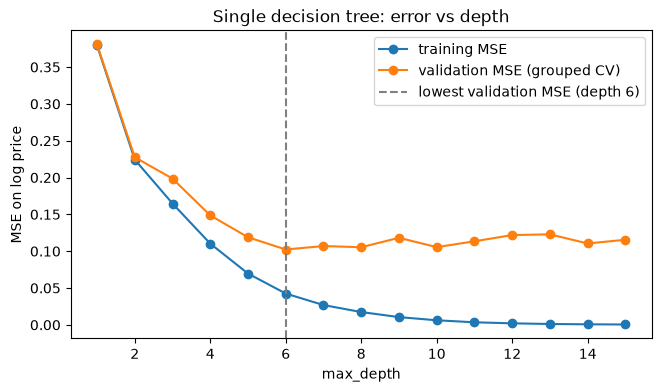

,R² (log price),median % error,MAE (₹)
model,,,
Decision tree (depth 3),0.675 ± 0.032,26.4 ± 3.0,"15,836 ± 1,846"
Decision tree (best depth),0.832 ± 0.028,16.1 ± 2.1,"11,346 ± 1,226"


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(depths, train_mse.mean(axis=1), marker="o", label="training MSE")
ax.plot(depths, val_mse.mean(axis=1), marker="o", label="validation MSE (grouped CV)")
ax.axvline(best_depth, color="gray", linestyle="--", label=f"lowest validation MSE (depth {best_depth})")
ax.set(title="Single decision tree: error vs depth", xlabel="max_depth", ylabel="MSE on log price")
ax.legend()
plt.show()

cv_results["Decision tree (best depth)"], oof["Decision tree (best depth)"] = cross_validate(
    make_tree_pipeline(DecisionTreeRegressor(max_depth=best_depth, random_state=42)), train)
show([summary_row(n, f) for n, f in cv_results.items()])

**Takeaway — the classic bias–variance picture.** Training MSE falls steadily with depth, from 0.379 at depth 1 to 0.0005 at depth 15 (the deepest trees almost memorise every training phone). Validation MSE falls until **depth 6 (0.102)** and then stops improving: from depth 7 on it moves between 0.105 and 0.123 while the training error keeps dropping.
- **Depth 1–5 underfit (high bias):** training and validation errors are both high and close together (depth 3: 0.165 vs 0.199). The tree is too simple.
- **Beyond depth 6 the tree overfits (high variance):** the gap between training and validation error widens (depth 6: 0.043 vs 0.102; depth 12: 0.002 vs 0.122). Extra questions fit the noise of particular training phones, not patterns that carry over to new phones.
- The best single tree (depth 6) reaches **R² 0.832** and a median error of **16.1 %**. Its median error is already better than ridge's (18.3 %), but its R² is lower (0.847): it prices typical phones well but makes some large mistakes, which R² (based on squared errors) punishes.

## 6.3 Random forest
A single deep tree has high variance: small changes in the training phones change its splits a lot. A **random forest** averages many deep trees that are made deliberately different from each other (**bagging** = **b**ootstrap **agg**regat**ing**):
- Each tree is trained on a **bootstrap sample**: as many phones as the training set, drawn *with replacement*, so some phones appear twice and some not at all.
- At each split a tree may only consider a random subset of the features (**`max_features`**: e.g. "sqrt" = √(number of columns), or 0.5 = half of them). This stops every tree from asking the same first question.

Each tree is noisy, but their errors partly cancel when averaged, so the forest has much lower variance than one tree. Other settings: **`n_estimators`** = number of trees, **`max_depth`** = depth limit per tree (None = grow until leaves are pure), **`min_samples_leaf`** = minimum number of phones in a leaf (larger = smoother).

Forests also offer an **out-of-bag score** (each tree scored on the phones its bootstrap sample left out). We do **not** use it: it ignores our phone groups, so a phone could be scored by trees that trained on its own storage variant, which leaks. We tune with the saved grouped folds instead.

In [13]:
rf_grid = {"model__n_estimators": [200, 500], "model__max_depth": [None, 10, 20],
           "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.5]}
rf_search = GridSearchCV(make_tree_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)), rf_grid,
                         cv=cv_folds(train), scoring="neg_mean_squared_error", n_jobs=-1)
rf_search.fit(train[FEATURES], y)

rf_table = pd.DataFrame(rf_search.cv_results_)
rf_table = rf_table.assign(**{"CV MSE": -rf_table["mean_test_score"], "std": rf_table["std_test_score"]})
cols = ["param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf",
        "param_model__max_features", "CV MSE", "std"]
print("Top 5 of", len(rf_table), "settings (lowest CV MSE first):")
rf_table.sort_values("CV MSE")[cols].head(5).round(4)

Top 5 of 36 settings (lowest CV MSE first):


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,CV MSE,std
1,500,None,1,sqrt,0.0560,0.0125
25,500,20,1,sqrt,0.0562,0.0125
0,200,None,1,sqrt,0.0571,0.0132
24,200,20,1,sqrt,0.0573,0.0131
7,500,None,1,0.5,0.0574,0.0140


Grouped-CV score of the chosen forest (refitted in each fold with the plain fold loop).

In [14]:
forest_pipe = clone(rf_search.best_estimator_)      # chosen settings, not yet fitted
print("chosen:", rf_search.best_params_)
cv_results["Random forest"], oof["Random forest"] = cross_validate(forest_pipe, train)
show([summary_row(n, f) for n, f in cv_results.items()])

chosen: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 500}


,R² (log price),median % error,MAE (₹)
model,,,
Decision tree (depth 3),0.675 ± 0.032,26.4 ± 3.0,"15,836 ± 1,846"
Decision tree (best depth),0.832 ± 0.028,16.1 ± 2.1,"11,346 ± 1,226"
Random forest,0.909 ± 0.014,13.2 ± 1.7,"9,350 ± 1,805"


**Takeaway — averaging many trees fixes the single tree's variance.** The chosen forest has **500 trees, no depth limit, min_samples_leaf = 1 and max_features = "sqrt"** (about 6 of the 33 encoded columns per split). All of the top 5 settings use leaves of 1 phone, and "sqrt" beats 0.5. Fully grown, very different trees are best because averaging takes care of their variance. 500 trees are only slightly better than 200 (CV MSE 0.0560 vs 0.0571), and max_depth 20 is practically the same as no limit (0.0562).

The forest reaches grouped-CV **R² 0.909 ± 0.014**, a median error of **13.2 %** and MAE **₹9,350**. Its CV MSE (0.056) is about half that of the best single tree (0.102), and the R² is 0.06 above ridge.

## 6.4 Gradient boosting
**Boosting** builds trees one after another instead of independently. It starts from a constant prediction (the mean log price). Each new **small** tree is fitted to the current **residuals** (actual − predicted log price) of the model so far, i.e. it learns what the model still gets wrong. Its prediction is then added, multiplied by the **learning rate** (a small step size such as 0.05).
- A large learning rate takes big steps: few trees are needed, but the model overfits sooner.
- A small learning rate takes many small steps: slower, but each tree corrects only a little, which is safer.
- **`subsample`** = 0.8 trains each tree on a random 80 % of the phones (without replacement), which adds some randomness, as in a forest, and often reduces overfitting.

We tune the number of trees, the learning rate, the tree depth (small trees: 2–4) and subsample with the same grouped folds.

In [15]:
gb_grid = {"model__n_estimators": [200, 400, 800], "model__learning_rate": [0.03, 0.05, 0.1],
           "model__max_depth": [2, 3, 4], "model__subsample": [1.0, 0.8]}
gb_search = GridSearchCV(make_tree_pipeline(GradientBoostingRegressor(random_state=42)), gb_grid,
                         cv=cv_folds(train), scoring="neg_mean_squared_error", n_jobs=-1)
gb_search.fit(train[FEATURES], y)

gb_table = pd.DataFrame(gb_search.cv_results_)
gb_table = gb_table.assign(**{"CV MSE": -gb_table["mean_test_score"], "std": gb_table["std_test_score"]})
cols = ["param_model__n_estimators", "param_model__learning_rate", "param_model__max_depth",
        "param_model__subsample", "CV MSE", "std"]
print("chosen:", gb_search.best_params_)
print("Top 5 of", len(gb_table), "settings (lowest CV MSE first):")
gb_table.sort_values("CV MSE")[cols].head(5).round(4)

chosen: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.8}
Top 5 of 54 settings (lowest CV MSE first):


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__subsample,CV MSE,std
49,200,0.10,4,0.8,0.0524,0.0099
51,400,0.10,4,0.8,0.0527,0.0099
53,800,0.10,4,0.8,0.0534,0.0098
17,800,0.03,4,0.8,0.0540,0.0114
33,400,0.05,4,0.8,0.0541,0.0126


**How many trees are enough?** For the chosen learning rate, depth and subsample, we fit 800 trees in each fold and use `staged_predict`, which gives the prediction after 1 tree, after 2 trees, …, after 800 trees. Averaging the validation MSE over folds shows where adding more trees stops helping.

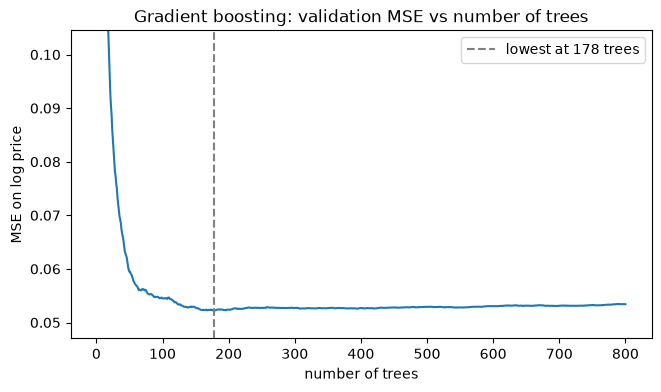

lowest validation MSE 0.0522 after 178 trees
validation MSE after 50 trees: 0.0595
validation MSE after 100 trees: 0.0545
validation MSE after 200 trees: 0.0524
validation MSE after 400 trees: 0.0527
validation MSE after 800 trees: 0.0534


In [16]:
gb_best = gb_search.best_params_
n_max = 800
stage_mse = np.zeros((5, n_max))
for k, (fit_idx, val_idx) in enumerate(cv_folds(train)):
    fit, val = train.iloc[fit_idx], train.iloc[val_idx]
    pipe = make_tree_pipeline(GradientBoostingRegressor(
        n_estimators=n_max, learning_rate=gb_best["model__learning_rate"], max_depth=gb_best["model__max_depth"],
        subsample=gb_best["model__subsample"], random_state=42)).fit(fit[FEATURES], fit["log_price"])
    X_val = pipe.named_steps["pre"].transform(val[FEATURES])
    for i, pred in enumerate(pipe.named_steps["model"].staged_predict(X_val)):   # after 1, 2, ... trees
        stage_mse[k, i] = np.mean((pred - val["log_price"]) ** 2)

curve = stage_mse.mean(axis=0)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(1, n_max + 1), curve)
ax.axvline(curve.argmin() + 1, color="gray", linestyle="--", label=f"lowest at {curve.argmin() + 1} trees")
ax.set(title="Gradient boosting: validation MSE vs number of trees", xlabel="number of trees", ylabel="MSE on log price",
       ylim=(curve.min() * 0.9, curve.min() * 2))
ax.legend()
plt.show()
print(f"lowest validation MSE {curve.min():.4f} after {curve.argmin() + 1} trees")
for n in [50, 100, 200, 400, 800]:
    print(f"validation MSE after {n} trees: {curve[n - 1]:.4f}")

Grouped-CV score of the chosen boosting model.

In [17]:
boost_pipe = clone(gb_search.best_estimator_)
cv_results["Gradient boosting"], oof["Gradient boosting"] = cross_validate(boost_pipe, train)
show([summary_row(n, f) for n, f in cv_results.items()])

,R² (log price),median % error,MAE (₹)
model,,,
Decision tree (depth 3),0.675 ± 0.032,26.4 ± 3.0,"15,836 ± 1,846"
Decision tree (best depth),0.832 ± 0.028,16.1 ± 2.1,"11,346 ± 1,226"
Random forest,0.909 ± 0.014,13.2 ± 1.7,"9,350 ± 1,805"
Gradient boosting,0.914 ± 0.015,12.7 ± 1.7,"8,880 ± 1,968"


**Optional: XGBoost.** XGBoost is a separate, faster implementation of gradient boosting. If the `xgboost` package is installed, we run it with the same number of trees, learning rate and depth; otherwise this cell does nothing.

In [18]:
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

if XGBRegressor is not None:
    xgb_pipe = make_tree_pipeline(XGBRegressor(
        n_estimators=gb_best["model__n_estimators"], learning_rate=gb_best["model__learning_rate"],
        max_depth=gb_best["model__max_depth"], subsample=gb_best["model__subsample"], random_state=42, n_jobs=-1))
    cv_results["XGBoost"], oof["XGBoost"] = cross_validate(xgb_pipe, train)
    print(show([summary_row("XGBoost", cv_results["XGBoost"])]))

**Takeaway — boosting is the best single model, by a small margin over the forest.** The chosen settings are **learning rate 0.1, trees of depth 4, 200 trees, subsample 0.8**. All of the top 5 settings use depth 4 and subsample 0.8. Depth 4 is the largest depth in the grid, so slightly deeper trees might help a little; we keep the grid from the plan.
- **Number of trees:** the validation error drops quickly up to about 100 trees (MSE 0.0545), reaches its lowest point at **178 trees (0.0522)** and then stays almost flat, creeping up very slowly (0.0534 at 800 trees). With learning rate 0.1, adding trees after about 200 no longer helps, and overfitting is very slow.
- **Score:** grouped-CV **R² 0.914 ± 0.015**, median error **12.7 %**, MAE **₹8,880**. That is slightly better than the forest (0.909, 13.2 %), but the difference is well inside the fold-to-fold spread.
- XGBoost is not installed in this environment, so the optional XGBoost cell was skipped.

## 6.4b AdaBoost
**AdaBoost** ("adaptive boosting") also builds trees one after another, but it learns from its mistakes in a different way than gradient boosting:
- **Gradient boosting** fits each new tree to the **residuals** (what the model so far still gets wrong).
- **AdaBoost** keeps a **weight** for every phone. Each new tree is trained on the phones drawn according to these weights. After the tree is added, the phones it predicted badly get a **higher weight**, so the next tree concentrates on them. The final prediction is a **weighted median** of all trees' predictions, where more accurate trees get a bigger say.

sklearn's `AdaBoostRegressor` implements the version for regression, **AdaBoost.R2**. We tune four settings with the same grouped folds:
- **`n_estimators`:** the number of trees.
- **`learning_rate`:** how strongly each round changes the weights (smaller = more careful).
- **`loss`:** how a phone's error is turned into its new weight. "linear" uses the error itself, "square" its square, and "exponential" grows fastest, so with "square" and "exponential" the worst-predicted phones dominate.
- **`max_depth`:** the depth of each tree.

In [19]:
ada_grid = {"model__n_estimators": [100, 300, 500], "model__learning_rate": [0.05, 0.1, 0.3, 1.0],
            "model__loss": ["linear", "square", "exponential"], "model__estimator__max_depth": [3, 5, 8]}
ada_model = AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=42), random_state=42)
ada_search = GridSearchCV(make_tree_pipeline(ada_model), ada_grid, cv=cv_folds(train),
                          scoring="neg_mean_squared_error", n_jobs=-1)
ada_search.fit(train[FEATURES], y)

ada_table = pd.DataFrame(ada_search.cv_results_)
ada_table = ada_table.assign(**{"CV MSE": -ada_table["mean_test_score"], "std": ada_table["std_test_score"]})
cols = ["param_model__n_estimators", "param_model__learning_rate", "param_model__loss",
        "param_model__estimator__max_depth", "CV MSE", "std"]
print("chosen:", ada_search.best_params_)
print("Top 5 of", len(ada_table), "settings (lowest CV MSE first):")
ada_table.sort_values("CV MSE")[cols].head(5).round(4)

chosen: {'model__estimator__max_depth': 8, 'model__learning_rate': 1.0, 'model__loss': 'exponential', 'model__n_estimators': 300}
Top 5 of 108 settings (lowest CV MSE first):


,param_model__n_estimators,param_model__learning_rate,param_model__loss,param_model__estimator__max_depth,CV MSE,std
106,300,1.0,exponential,8,0.0518,0.0126
101,500,1.0,linear,8,0.0520,0.0140
94,300,0.3,square,8,0.0524,0.0147
95,500,0.3,square,8,0.0525,0.0139
104,500,1.0,square,8,0.0527,0.0140


Grouped-CV score of the chosen AdaBoost model (plain fold loop), next to the other tree ensembles.

In [20]:
ada_pipe = clone(ada_search.best_estimator_)
cv_results["AdaBoost"], oof["AdaBoost"] = cross_validate(ada_pipe, train)
show([summary_row(n, cv_results[n]) for n in ["Random forest", "Gradient boosting", "AdaBoost"]])

,R² (log price),median % error,MAE (₹)
model,,,
Random forest,0.909 ± 0.014,13.2 ± 1.7,"9,350 ± 1,805"
Gradient boosting,0.914 ± 0.015,12.7 ± 1.7,"8,880 ± 1,968"
AdaBoost,0.916 ± 0.019,11.6 ± 1.2,"8,455 ± 1,896"


**Does AdaBoost suffer from doubtful prices?** AdaBoost gives more and more weight to phones it predicts badly. If a phone's India price is wrong, no model can predict it well, so AdaBoost may keep focusing on it. Notebook 01 flagged phones whose India price is doubtful (`india_price_flag`). We compare the out-of-fold median % error on the flagged and the other training phones for gradient boosting and AdaBoost.

In [21]:
flagged = train["india_price_flag"].fillna("") != ""
print(f"flagged training phones: {flagged.sum()} of {len(train)}")
error_by_flag = {}
for name in ["Gradient boosting", "AdaBoost"]:
    pct = 100 * np.abs(np.exp(oof[name]) / train["price_inr"] - 1)   # out-of-fold % error per phone
    error_by_flag[name] = {"flagged phones": pct[flagged].median(), "other phones": pct[~flagged].median()}
pd.DataFrame(error_by_flag).T.round(1)

flagged training phones: 22 of 558


,flagged phones,other phones
Gradient boosting,25.4,12.8
AdaBoost,25.3,11.2


**Takeaway — AdaBoost is as accurate as gradient boosting.**
- **Chosen settings:** 300 trees of depth 8, learning rate 1.0, "exponential" loss. Depth 8 and learning rate 1.0 are the largest values in the grid, so even larger values might score slightly better. All of the top 5 settings use depth-8 trees, so AdaBoost prefers fairly deep trees here, unlike gradient boosting (depth 4).
- **Score:** grouped-CV **R² 0.916 ± 0.019**, median error **11.6 %**, MAE **₹8,455**. That is a little better on average than gradient boosting (0.914, 12.7 %, ₹8,880) and the random forest (0.909, 13.2 %).
- **But the gap is within the noise:** fold by fold, AdaBoost beats gradient boosting in 3 folds and loses in 2. The R² differences run from −0.018 to +0.018 and the median-error differences from −1.3 to +3.1 points, so AdaBoost and gradient boosting are a **tie** on this data.
- **Doubtful prices do not hurt AdaBoost more:** on the 22 flagged training phones, AdaBoost and gradient boosting have the same median error (25.3 % vs 25.4 %, about twice their error on the other phones). AdaBoost's re-weighting of hard phones did not make it worse on them.

## 6.5 Which features matter? Permutation importance
**Permutation importance:** take the validation phones, randomly **shuffle one feature's values** among them (so that feature no longer carries information, while everything else stays the same), and measure how much the validation MSE rises. A big rise means the model relied on that feature; no rise means it could do without it. We repeat each shuffle 20 times and average.

We shuffle the **raw columns before encoding**, so "brand" (14 dummy columns after encoding) and "chip_group" are each treated as **one** feature. We do it inside each grouped fold (fit on the fold's training part, shuffle on its validation part) and average over the 5 folds; the error bars show the fold-to-fold spread (± 1 std).

In [22]:
importance = {"Random forest": [], "Gradient boosting": []}   # one array per fold
for fit_idx, val_idx in cv_folds(train):
    fit, val = train.iloc[fit_idx], train.iloc[val_idx]
    for name, pipe in [("Random forest", forest_pipe), ("Gradient boosting", boost_pipe)]:
        model = clone(pipe).fit(fit[FEATURES], fit["log_price"])
        result = permutation_importance(model, val[FEATURES], val["log_price"], n_repeats=20,
                                        scoring="neg_mean_squared_error", random_state=42, n_jobs=-1)
        importance[name].append(result.importances_mean)   # rise in MSE when the column is shuffled

imp_mean = pd.DataFrame({n: np.mean(v, axis=0) for n, v in importance.items()}, index=FEATURES)
imp_std = pd.DataFrame({n: np.std(v, axis=0, ddof=1) for n, v in importance.items()}, index=FEATURES)
imp_mean.sort_values("Gradient boosting", ascending=False).round(4)

,Random forest,Gradient boosting
chip_group,0.1508,0.2977
log2_ram,0.0640,0.1028
front_mp,0.0421,0.0641
brand,0.0455,0.0393
weight_g,0.0319,0.0355
log2_storage,0.0351,0.0253
screen_in,0.0226,0.0154
battery_mah,0.0234,0.0147
year,0.0069,0.0121
main_back_mp,0.0086,0.0046


The same numbers as bar charts, features in the same order in both panels (sorted by the boosting importance).

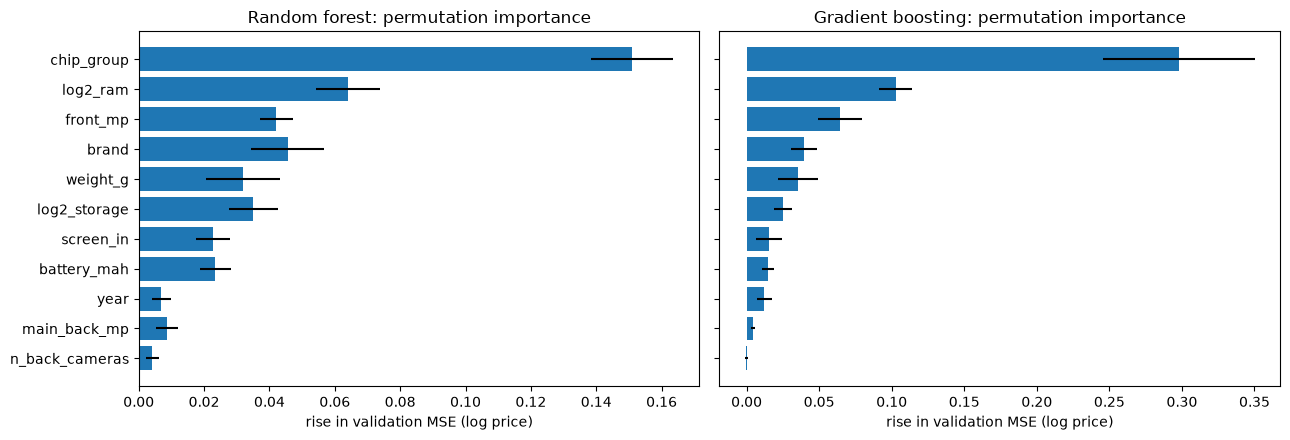

In [23]:
order = imp_mean["Gradient boosting"].sort_values().index      # same feature order in both panels
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, name in zip(axes, ["Random forest", "Gradient boosting"]):
    ax.barh(order, imp_mean.loc[order, name], xerr=imp_std.loc[order, name])
    ax.set(title=f"{name}: permutation importance", xlabel="rise in validation MSE (log price)")
fig.tight_layout()
plt.show()

**Comparison with the linear models.** Two linear views of "importance" from Phase 5:
- **Lasso drop-out α:** the penalty strength at which the lasso sets a feature to zero for good (larger = kept longer = more useful). For brand and chip_group we use the α at which *all* their dummies are zero.
- **Ridge coefficient size** (at Phase 5's α, standardised numerics): for a numeric feature, |coefficient| = change in log price per 1 standard deviation; for brand and chip_group, the **spread** between the highest and lowest dummy coefficient (the price gap between the most and least expensive category). The units differ, so compare ranks rather than values.

In [24]:
lasso_alphas = np.logspace(-4, 0, 50)
lasso_path = {}
for a in lasso_alphas:   # lasso refitted on the whole training set for every α (as in notebook 04)
    pipe = make_linear_pipeline(Lasso(alpha=a, max_iter=50000)).fit(train[FEATURES], y)
    lasso_path[a] = pd.Series(pipe.named_steps["model"].coef_, index=clean_names(pipe))
lasso_path = pd.DataFrame(lasso_path).T

ridge_pipe = make_linear_pipeline(Ridge(alpha=ridge_alpha)).fit(train[FEATURES], y)
ridge_coef = pd.Series(ridge_pipe.named_steps["model"].coef_, index=clean_names(ridge_pipe))

linear_view = {}
for feature in FEATURES:
    cols = [c for c in lasso_path.columns if c == feature or c.startswith(feature + "_")]
    nonzero = (lasso_path[cols].abs() > 1e-10).any(axis=1).to_numpy()   # is ANY of its columns non-zero?
    last = np.where(nonzero)[0].max()
    dropped_at = lasso_alphas[last + 1] if last + 1 < len(lasso_alphas) else np.nan   # NaN: never dropped
    size = abs(ridge_coef[feature]) if feature in NUMERIC_FEATURES else np.ptp(ridge_coef[cols])
    linear_view[feature] = {"lasso drop-out α": dropped_at, "ridge |coef| or spread": size}

All four views side by side, with ranks (1 = most important) so they can be compared despite the different units.

In [25]:
compare = pd.DataFrame(linear_view).T
compare["forest importance"] = imp_mean["Random forest"]
compare["boosting importance"] = imp_mean["Gradient boosting"]
ranks = pd.DataFrame({  # 1 = most important; never-dropped features share the top lasso rank
    "lasso rank": compare["lasso drop-out α"].fillna(np.inf).rank(ascending=False, method="min"),
    "ridge rank": compare["ridge |coef| or spread"].rank(ascending=False),
    "forest rank": compare["forest importance"].rank(ascending=False),
    "boosting rank": compare["boosting importance"].rank(ascending=False)}).astype(int)
pd.concat([compare.round(4), ranks], axis=1).sort_values("boosting rank")

,lasso drop-out α,ridge |coef| or spread,forest importance,boosting importance,lasso rank,ridge rank,forest rank,boosting rank
chip_group,0.1842,0.8596,0.1508,0.2977,5,2,1,1
log2_ram,0.2683,0.2496,0.0640,0.1028,2,3,2,2
front_mp,0.0193,0.0388,0.0421,0.0641,8,10,4,3
brand,0.0596,1.0976,0.0455,0.0393,6,1,3,4
weight_g,0.2223,0.1101,0.0319,0.0355,4,5,6,5
log2_storage,0.5690,0.0946,0.0351,0.0253,1,6,5,6
screen_in,0.0052,0.0487,0.0226,0.0154,9,8,8,7
battery_mah,0.2683,0.1628,0.0234,0.0147,2,4,7,8
year,0.0494,0.0728,0.0069,0.0121,7,7,10,9
main_back_mp,0.0002,0.0011,0.0086,0.0046,11,11,9,10


**Takeaway — where the four views agree and disagree.**
- **Agreement:** the **chip group** matters most for both tree models: shuffling it raises the validation MSE by 0.15 (forest) and 0.30 (boosting), far more than any other feature. **RAM** is second for both trees and among the top 3 for ridge and lasso. **Main camera megapixels** and the **number of back cameras** are at or near the bottom of all four lists (the lasso drops main camera MP first), and **launch year** is low everywhere.
- **Front camera MP is the big disagreement:** it ranks 3rd–4th for the trees but 8th (lasso) and 10th (ridge) for the linear models. As the depth-3 tree showed, a big front camera marks the Chinese brands (median 16–32 MP) and a small one marks Apple, Samsung and Google (10–12 MP). A tree can use it as a shortcut to split brands *inside* a chip tier, which is an interaction. In a linear model the brand dummies already carry the brand's average effect, so the front camera adds almost nothing.
- **Brand** is ranked 1st by ridge (a spread of 1.10 in log price between the most and least expensive brand, about a factor of 3) but only 3rd–4th by the trees. Permutation importance only measures what is lost when a feature is shuffled *while the others stay*. Much of the brand information is still available through the chip and the front camera, so shuffling brand costs less. Correlated features **share or steal** importance.
- **RAM vs storage:** the trees rank RAM well above storage (2nd vs 5th–6th), while the lasso keeps storage longest of all features. This is the same instability as in Phases 4–5: RAM and storage are correlated, so a model can lean on either one. The lasso keeps one of them, and the trees mostly split on RAM.
- **Battery** ranks 2nd–4th for the linear models but 7th–8th for the trees. Its negative linear coefficient (budget "battery champion" phones) is a correction that trees make through other splits instead.

## 6.6 Where do trees beat ridge? Interactions
An **interaction** means the effect of one feature depends on another, e.g. a brand's premium being larger for flagship phones than for budget phones. A linear model on log price adds up one effect per feature, so it cannot represent this unless we add an interaction column; a tree can, by asking about brand *after* asking about the chip. Phase 4's residuals hinted at exactly this (Samsung and Oppo, which sell from budget phones to foldables, had the widest spread).

We compare **out-of-fold predictions** (each phone predicted by the model fitted without its fold) of ridge (Phase 5's α), the forest and boosting, by price band and for the 6 biggest brands. The error per phone is |predicted price / actual price − 1|; we report the median per group.

In [26]:
cv_ridge, oof["Ridge"] = cross_validate(make_linear_pipeline(Ridge(alpha=ridge_alpha)), train)
print(f"ridge CV R² here: {cv_ridge['R²'].mean():.4f} (Phase 5 table: {phase5.set_index('model').loc['Ridge', 'R2_log_mean']:.4f})")

models = ["Ridge", "Random forest", "Gradient boosting"]
pct_error = pd.DataFrame({m: 100 * np.abs(np.exp(oof[m]) / train["price_inr"] - 1) for m in models})
band = pd.cut(train["price_inr"], [0, 15000, 30000, 60000, np.inf], right=False,
              labels=["< ₹15k", "₹15–30k", "₹30–60k", "₹60k+"])
by_band = pct_error.groupby(band, observed=True).median().assign(phones=band.value_counts())
top_brands = train["brand"].value_counts().index[:6]
in_top = train["brand"].isin(top_brands)
by_brand = pct_error[in_top].groupby(train.loc[in_top, "brand"]).median().assign(phones=train["brand"].value_counts())
print("Median % error by price band:\n", by_band.round(1).to_string())
print("\nMedian % error for the 6 biggest brands:\n", by_brand.loc[top_brands].round(1).to_string())

ridge CV R² here: 0.8472 (Phase 5 table: 0.8472)
Median % error by price band:
            Ridge  Random forest  Gradient boosting  phones
price_inr                                                 
< ₹15k      13.5            8.5                8.1      86
₹15–30k     21.8           14.4               13.0     170
₹30–60k     21.1           12.6               14.5     137
₹60k+       15.4           15.7               13.9     165

Median % error for the 6 biggest brands:
           Ridge  Random forest  Gradient boosting  phones
brand                                                    
Oppo       33.6           13.5               15.0      94
Samsung    38.4           13.9               14.1      65
Apple      10.6           10.6                8.8      59
Vivo       13.9           15.8               15.9      51
Motorola   17.4           12.2               13.4      50
Realme     11.3           12.4               12.5      47


The same medians as grouped bar charts.

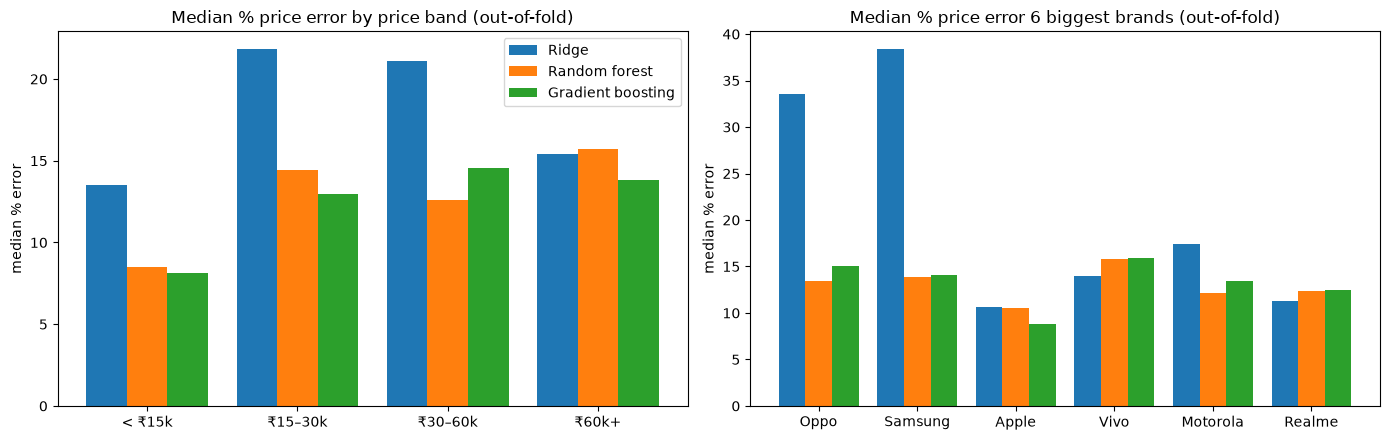

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, table, title in [(axes[0], by_band, "by price band"), (axes[1], by_brand.loc[top_brands], "6 biggest brands")]:
    x = np.arange(len(table))
    for j, m in enumerate(models):
        ax.bar(x + (j - 1) * 0.27, table[m], width=0.27, label=m)
    ax.set_xticks(x, table.index)
    ax.set(title=f"Median % price error {title} (out-of-fold)", ylabel="median % error")
axes[0].legend()
fig.tight_layout()
plt.show()

**One simple interaction test.** We give ridge one extra set of columns: **flagship chip × brand** (for each brand, a column that is 1 only for that brand's flagship-chip phones). Ridge can then give each brand a different premium for its flagship phones than for its other phones. We re-tune α with the same grid and folds and rerun the grouped CV. If this closes much of the gap to the trees, then this interaction is a large part of what the trees find.

In [28]:
train_int = train.copy()
is_flagship = (train["chip_group"] == "flagship_sd8_or_apple").astype(float)
interaction_cols = []
for b in sorted(train["brand"].unique()):
    col = f"flagship_x_{b}"
    train_int[col] = is_flagship * (train["brand"] == b)    # 1 only for brand b's flagship-chip phones
    interaction_cols.append(col)
numeric_int = NUMERIC_FEATURES + interaction_cols

int_search = GridSearchCV(make_linear_pipeline(Ridge(), numeric=numeric_int), {"model__alpha": np.logspace(-3, 3, 50)},
                          cv=cv_folds(train_int), scoring="neg_mean_squared_error", n_jobs=-1)
int_search.fit(train_int[numeric_int + CATEGORICAL], y)
int_alpha = int_search.best_params_["model__alpha"]
cv_results["Ridge + flagship×brand"], oof["Ridge + flagship×brand"] = cross_validate(
    make_linear_pipeline(Ridge(alpha=int_alpha), numeric=numeric_int), train_int, features=numeric_int + CATEGORICAL)
print(f"chosen α with interactions: {int_alpha:.3g}")
show([summary_row("Ridge", cv_ridge)] + [summary_row(n, cv_results[n]) for n in
      ["Ridge + flagship×brand", "Random forest", "Gradient boosting"]])

chosen α with interactions: 1.53


,R² (log price),median % error,MAE (₹)
model,,,
Ridge,0.847 ± 0.019,18.3 ± 2.4,"11,588 ± 1,767"
Ridge + flagship×brand,0.841 ± 0.025,18.8 ± 2.8,"12,050 ± 2,302"
Random forest,0.909 ± 0.014,13.2 ± 1.7,"9,350 ± 1,805"
Gradient boosting,0.914 ± 0.015,12.7 ± 1.7,"8,880 ± 1,968"


**Takeaway — the trees' gain comes mostly from Samsung and Oppo, and one flagship × brand interaction does not explain it.**
- **By price band:** the trees are much better for phones under ₹60,000 (median error 8–15 % vs ridge's 13.5–21.8 %). Above ₹60,000 all three models are similar (ridge 15.4 %, forest 15.7 %, boosting 13.9 %).
- **By brand:** almost the whole gap is **Samsung** (ridge 38.4 % vs trees 13.9–14.1 %) and **Oppo** (33.6 % vs 13.5–15.0 %), with a smaller gain for Motorola (17.4 % vs 12.2–13.4 %). For Apple the models are about equal (8.8–10.6 %), and for Vivo and Realme ridge is even slightly better.
- **Why:** Samsung and Oppo sell everything from ₹10,000 phones to foldables, but ridge gives each brand one premium for all its phones. Its out-of-fold predictions are too high for their cheap phones (by about +0.3 to +0.45 in log price, i.e. 35–55 % too expensive) and too low for their expensive ones (about −0.2 to −0.3). The trees can give a different "brand effect" in each tier. This is the interaction Phase 4's residuals hinted at.
- **The interaction test fails:** ridge + flagship × brand scores R² **0.841** and **18.8 %**, slightly *worse* than plain ridge (0.847, 18.3 %). The tier gap is not about the flagship chip. Samsung's flagship-chip phones were already priced well by ridge (median residual 0.00), and its budget-to-upper-mid phones share the same `exynos` chip group. So the 14 new columns add noise rather than signal. The real interaction is closer to brand × price tier *within* the same chip group, which the trees build from combinations of RAM, weight, front camera and chip.

**Save the out-of-fold predictions** (log price) for later phases, with the columns needed to group them.

In [29]:
oof_table = train[["model_group", "brand", "chip_group", "price_inr", "log_price", "fold"]].copy()
for name, pred in oof.items():
    oof_table["oof_" + name] = pred
oof_table.to_csv("../results/oof_predictions_phase6.csv", index_label="row")
print("Saved results/oof_predictions_phase6.csv with columns:", list(oof_table.columns))

Saved results/oof_predictions_phase6.csv with columns: ['model_group', 'brand', 'chip_group', 'price_inr', 'log_price', 'fold', 'oof_Decision tree (depth 3)', 'oof_Decision tree (best depth)', 'oof_Random forest', 'oof_Gradient boosting', 'oof_AdaBoost', 'oof_Ridge', 'oof_Ridge + flagship×brand']


## 6.7 Comparison table (grouped CV on the training set)
The Phase 5 rows are read from `results/cv_phase5.csv`; the tree rows are added below, all with the same folds and metrics.

In [30]:
tree_models = ["Decision tree (depth 3)", "Decision tree (best depth)", "Random forest", "Gradient boosting", "AdaBoost"]
tree_models += ["XGBoost"] if "XGBoost" in cv_results else []
rows = phase5.to_dict("records") + [summary_row(n, cv_results[n]) for n in tree_models]
pd.DataFrame(rows).to_csv("../results/cv_phase6.csv", index=False)
show(rows)

,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"
Ridge,0.847 ± 0.019,18.3 ± 2.4,"11,588 ± 1,767"
Lasso,0.848 ± 0.019,18.0 ± 2.1,"11,633 ± 1,807"
Elastic net,0.848 ± 0.019,18.1 ± 2.0,"11,617 ± 1,813"
Decision tree (depth 3),0.675 ± 0.032,26.4 ± 3.0,"15,836 ± 1,846"
Decision tree (best depth),0.832 ± 0.028,16.1 ± 2.1,"11,346 ± 1,226"


**Is the gain larger than the fold-to-fold spread?** The ± values above mix two things: how hard each fold is, and how good each model is. Because every model is scored on the **same** 5 validation folds, the fairer check is **paired**: compare the models fold by fold.

In [31]:
per_fold = pd.DataFrame({
    "Ridge R²": cv_ridge["R²"], "Forest R²": cv_results["Random forest"]["R²"],
    "Boosting R²": cv_results["Gradient boosting"]["R²"],
    "Ridge med %": cv_ridge["median % error"], "Boosting med %": cv_results["Gradient boosting"]["median % error"]})
per_fold["R² gain, boosting − ridge"] = per_fold["Boosting R²"] - per_fold["Ridge R²"]
per_fold["R² gain, forest − ridge"] = per_fold["Forest R²"] - per_fold["Ridge R²"]
per_fold["error cut, ridge − boosting (points)"] = per_fold["Ridge med %"] - per_fold["Boosting med %"]
per_fold["AdaBoost R²"] = cv_results["AdaBoost"]["R²"]
per_fold["R² gain, AdaBoost − boosting"] = per_fold["AdaBoost R²"] - per_fold["Boosting R²"]
per_fold["error cut, boosting − AdaBoost (points)"] = per_fold["Boosting med %"] - cv_results["AdaBoost"]["median % error"]
per_fold.index = [f"fold {k}" for k in range(1, 6)]
per_fold.round(3)

,Ridge R²,Forest R²,Boosting R²,Ridge med %,Boosting med %,"R² gain, boosting − ridge","R² gain, forest − ridge","error cut, ridge − boosting (points)",AdaBoost R²,"R² gain, AdaBoost − boosting","error cut, boosting − AdaBoost (points)"
fold 1,0.861,0.906,0.909,15.756,11.912,0.048,0.045,3.844,0.891,-0.018,-0.922
fold 2,0.841,0.899,0.895,19.490,14.488,0.053,0.058,5.002,0.912,0.018,2.082
fold 3,0.837,0.894,0.921,18.564,10.321,0.084,0.056,8.243,0.908,-0.013,-1.299
fold 4,0.872,0.929,0.934,16.363,12.579,0.062,0.057,3.784,0.939,0.005,2.759
fold 5,0.824,0.918,0.912,21.539,14.242,0.088,0.094,7.297,0.928,0.016,3.107


**Takeaway — the tree ensembles clearly beat every linear model.** Gradient boosting reaches grouped-CV **R² 0.914**, median error **12.7 %** and MAE **₹8,880**, against ridge's 0.847, 18.3 % and ₹11,588. That is **+0.067 R²**, about **5.6 points less median error**, and **₹2,700 less MAE**. The random forest is close behind (0.909, 13.2 %).

The paired check makes this convincing: boosting beats ridge in **all 5 folds**, by 0.048–0.088 R² and 3.8–8.2 points of median error, and so does the forest (by 0.045–0.094 R²). The fold-to-fold differences in the gain are much smaller than the gain itself, so it is not luck of the folds. Boosting vs forest is a tie: each wins some folds. **AdaBoost** (R² 0.916, 11.6 %) beats ridge in all 5 folds too, and is a tie with gradient boosting: it wins 3 folds and loses 2. The result is in line with the pilot's expectation for trees (R² ≈ 0.9).

**Caution.** The hyperparameters of every model were chosen with these same 5 folds, so each CV score is a little optimistic. Trees have more settings to tune than ridge (the forest grid has 36 combinations, gradient boosting 54, AdaBoost 108, ridge only α), so they had more chances to fit the folds by luck, and their CV scores are **more** optimistic. The untouched test set in Phase 7 is the fair comparison.

**Save all chosen settings** for Phase 7.

In [32]:
def plain(params):
    # GridSearchCV names ("model__alpha") -> plain names, numpy numbers -> Python numbers
    return {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

best_params = {
    "ridge": plain(lin_searches["ridge"].best_params_),
    "lasso": plain(lin_searches["lasso"].best_params_),
    "elastic_net": plain(lin_searches["elastic net"].best_params_),
    "decision_tree": {"max_depth": best_depth},
    "random_forest": plain(rf_search.best_params_),
    "gradient_boosting": plain(gb_search.best_params_),
    "adaboost": plain(ada_search.best_params_),
}
json.dump(best_params, open("../results/best_params.json", "w"), indent=2)
print(json.dumps(best_params, indent=2))

{
  "ridge": {
    "alpha": 1.5264179671752334
  },
  "lasso": {
    "alpha": 0.0013894954943731374
  },
  "elastic_net": {
    "alpha": 0.0017433288221999873,
    "l1_ratio": 0.8
  },
  "decision_tree": {
    "max_depth": 6
  },
  "random_forest": {
    "max_depth": null,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "n_estimators": 500
  },
  "gradient_boosting": {
    "learning_rate": 0.1,
    "max_depth": 4,
    "n_estimators": 200,
    "subsample": 0.8
  },
  "adaboost": {
    "estimator__max_depth": 8,
    "learning_rate": 1.0,
    "loss": "exponential",
    "n_estimators": 300
  }
}


## 6.8 Robustness: name-only training data
We refit the chosen forest and boosting settings without the 3 web-lookup phones in the training set (555 phones) and rerun their grouped CV.

In [33]:
rob = []
for name, pipe in [("Random forest", forest_pipe), ("Gradient boosting", boost_pipe)]:
    for label, data in [("with web lookup", train), ("name-only", train_name)]:
        folds, _ = cross_validate(pipe, data)
        rob.append({"model": name, "data": label, "phones": len(data), "CV R²": round(folds["R²"].mean(), 3),
                    "median % error": round(folds["median % error"].mean(), 1),
                    "MAE (₹)": round(folds["MAE (₹)"].mean())})
pd.DataFrame(rob)

,model,data,phones,CV R²,median % error,MAE (₹)
0,Random forest,with web lookup,558,0.909,13.2,9350
1,Random forest,name-only,555,0.913,13.4,9270
2,Gradient boosting,with web lookup,558,0.914,12.7,8880
3,Gradient boosting,name-only,555,0.913,12.2,8975


**Takeaway:** without the 3 web-lookup phones, both ensembles score the same within noise: forest R² 0.909 → 0.913 and boosting 0.914 → 0.913, with median errors moving by at most 0.5 points. The conclusions do not depend on the web-lookup phones.

## Summary
- **Best models:** AdaBoost (grouped-CV R² **0.916**, median error **11.6 %**), gradient boosting (0.914, 12.7 %) and the random forest (0.909, 13.2 %) beat ridge (0.847, 18.3 %) and every other linear model. Gradient boosting and the forest win in all 5 folds, by 0.05–0.09 R², so the gain over ridge is much larger than the fold-to-fold spread. The three ensembles are a tie with each other.
- **Readable rules:** a depth-3 tree (R² 0.675) first asks "flagship chip?", then RAM and weight for ordinary phones, and front camera and weight for flagships. The front camera is really a brand signal (Apple, Samsung and Google use small front cameras). A single tree is best at depth 6 (R² 0.832); deeper trees overfit.
- **Important features:** chip group first and RAM second in both tree models. Camera megapixels and the number of back cameras matter least for every model, including lasso. The models disagree on the front camera (important for trees as a brand proxy) and on RAM vs storage (correlated features share importance).
- **Where trees help:** almost entirely Samsung and Oppo phones below ₹60,000. Ridge gives each brand one premium for all its phones, but these brands span budget phones to foldables. A single flagship × brand interaction does *not* close the gap (R² 0.841): the interaction is brand × price tier within the same chip group, which trees find on their own.
- **Caution:** tree models had many more settings tuned on these same folds, so their CV scores are more optimistic than ridge's. The test set in Phase 7 is the fair check.
- **For Phase 7:** all chosen settings are saved in `results/best_params.json`. The main comparison will be **ridge vs random forest vs gradient boosting vs AdaBoost**, with the baselines, OLS, lasso, elastic net and the single trees as references.